**Consider Sales Dataset and analyse it in proper way.**

**Expectation:- Need a clarity on who is spending more money for shopping incase of  gender, age_group, state, Occuapation, Product_category, marital_status.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sales = pd.read_csv("sales_data (4).csv", encoding = 'ISO-8859-1')

In [3]:
sales.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [4]:
sales.shape

(11251, 15)

In [5]:
sales.info

<bound method DataFrame.info of        User_ID    Cust_name Product_ID Gender Age Group  Age  Marital_Status  \
0      1002903    Sanskriti  P00125942      F     26-35   28               0   
1      1000732       Kartik  P00110942      F     26-35   35               1   
2      1001990        Bindu  P00118542      F     26-35   35               1   
3      1001425       Sudevi  P00237842      M      0-17   16               0   
4      1000588         Joni  P00057942      M     26-35   28               1   
...        ...          ...        ...    ...       ...  ...             ...   
11246  1000695      Manning  P00296942      M     18-25   19               1   
11247  1004089  Reichenbach  P00171342      M     26-35   33               0   
11248  1001209        Oshin  P00201342      F     36-45   40               0   
11249  1004023       Noonan  P00059442      M     36-45   37               0   
11250  1002744      Brumley  P00281742      F     18-25   19               0   

       

In [6]:
# Checking duplicate data :
sales.duplicated().sum()

np.int64(8)

In [7]:
# Dropping the duplicate rows
sales.drop_duplicates(inplace = True)

In [8]:
sales.duplicated().sum()

np.int64(0)

In [9]:
sales

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0,NaN,NaN
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0,NaN,NaN
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0,NaN,NaN
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0,NaN,NaN


In [10]:
sales.isnull().sum().sum()

np.int64(22498)

In [11]:
# checking null values in status and unnamed1
sales['Status'].isnull().sum()

np.int64(11243)

In [12]:
sales['unnamed1'].isnull().sum()

np.int64(11243)

In [13]:
# Drop both the columns
sales.drop(['Status', 'unnamed1'], axis = 1, inplace = True)

In [14]:
sales.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [15]:
sales.info

<bound method DataFrame.info of        User_ID    Cust_name Product_ID Gender Age Group  Age  Marital_Status  \
0      1002903    Sanskriti  P00125942      F     26-35   28               0   
1      1000732       Kartik  P00110942      F     26-35   35               1   
2      1001990        Bindu  P00118542      F     26-35   35               1   
3      1001425       Sudevi  P00237842      M      0-17   16               0   
4      1000588         Joni  P00057942      M     26-35   28               1   
...        ...          ...        ...    ...       ...  ...             ...   
11246  1000695      Manning  P00296942      M     18-25   19               1   
11247  1004089  Reichenbach  P00171342      M     26-35   33               0   
11248  1001209        Oshin  P00201342      F     36-45   40               0   
11249  1004023       Noonan  P00059442      M     36-45   37               0   
11250  1002744      Brumley  P00281742      F     18-25   19               0   

       

In [16]:
# Checking the null values in amount column
sales['Amount'].isnull().sum()

np.int64(12)

In [17]:
# Deleting null rows
sales.dropna(inplace = True)

In [18]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11231 entries, 0 to 11250
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11231 non-null  int64  
 1   Cust_name         11231 non-null  object 
 2   Product_ID        11231 non-null  object 
 3   Gender            11231 non-null  object 
 4   Age Group         11231 non-null  object 
 5   Age               11231 non-null  int64  
 6   Marital_Status    11231 non-null  int64  
 7   State             11231 non-null  object 
 8   Zone              11231 non-null  object 
 9   Occupation        11231 non-null  object 
 10  Product_Category  11231 non-null  object 
 11  Orders            11231 non-null  int64  
 12  Amount            11231 non-null  float64
dtypes: float64(1), int64(4), object(8)
memory usage: 1.2+ MB


In [19]:
# Convert F to Female and M to Male
sales['Gender'] = sales['Gender'].str.replace('F', 'Female').str.replace('M', 'Male')

In [20]:
sales.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,Female,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,Female,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,Female,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,Male,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,Male,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0


In [21]:
sales['Marital_Status'].dtype

dtype('int64')

In [22]:
# Changing the datatype of Marital_Status
sales['Marital_Status'] = sales['Marital_Status'].astype(str)

In [23]:
sales['Marital_Status'] = sales['Marital_Status'].str.replace('0', 'Single').str.replace('1', 'Married')

In [24]:
sales.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,Female,26-35,28,Single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,Female,26-35,35,Married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,Female,26-35,35,Married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,Male,0-17,16,Single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,Male,26-35,28,Married,Gujarat,Western,Food Processing,Auto,2,23877.0


In [25]:
sales['State'].unique()

array(['Maharashtra', 'Andhra\xa0Pradesh', 'Uttar Pradesh', 'Karnataka',
       'Gujarat', 'Himachal Pradesh', 'Delhi', 'Jharkhand', 'Kerala',
       'Haryana', 'Madhya Pradesh', 'Bihar', 'Rajasthan', 'Uttarakhand',
       'Telangana', 'Punjab'], dtype=object)

In [26]:
# Removing the \xa0 from AndhraPradesh.
sales['State'] = sales['State'].str.replace('\xa0', ' ')

In [27]:
sales['State'].unique()

array(['Maharashtra', 'Andhra Pradesh', 'Uttar Pradesh', 'Karnataka',
       'Gujarat', 'Himachal Pradesh', 'Delhi', 'Jharkhand', 'Kerala',
       'Haryana', 'Madhya Pradesh', 'Bihar', 'Rajasthan', 'Uttarakhand',
       'Telangana', 'Punjab'], dtype=object)

In [28]:
def label(a):
    for i in a.containers:
        a.bar_label(i)

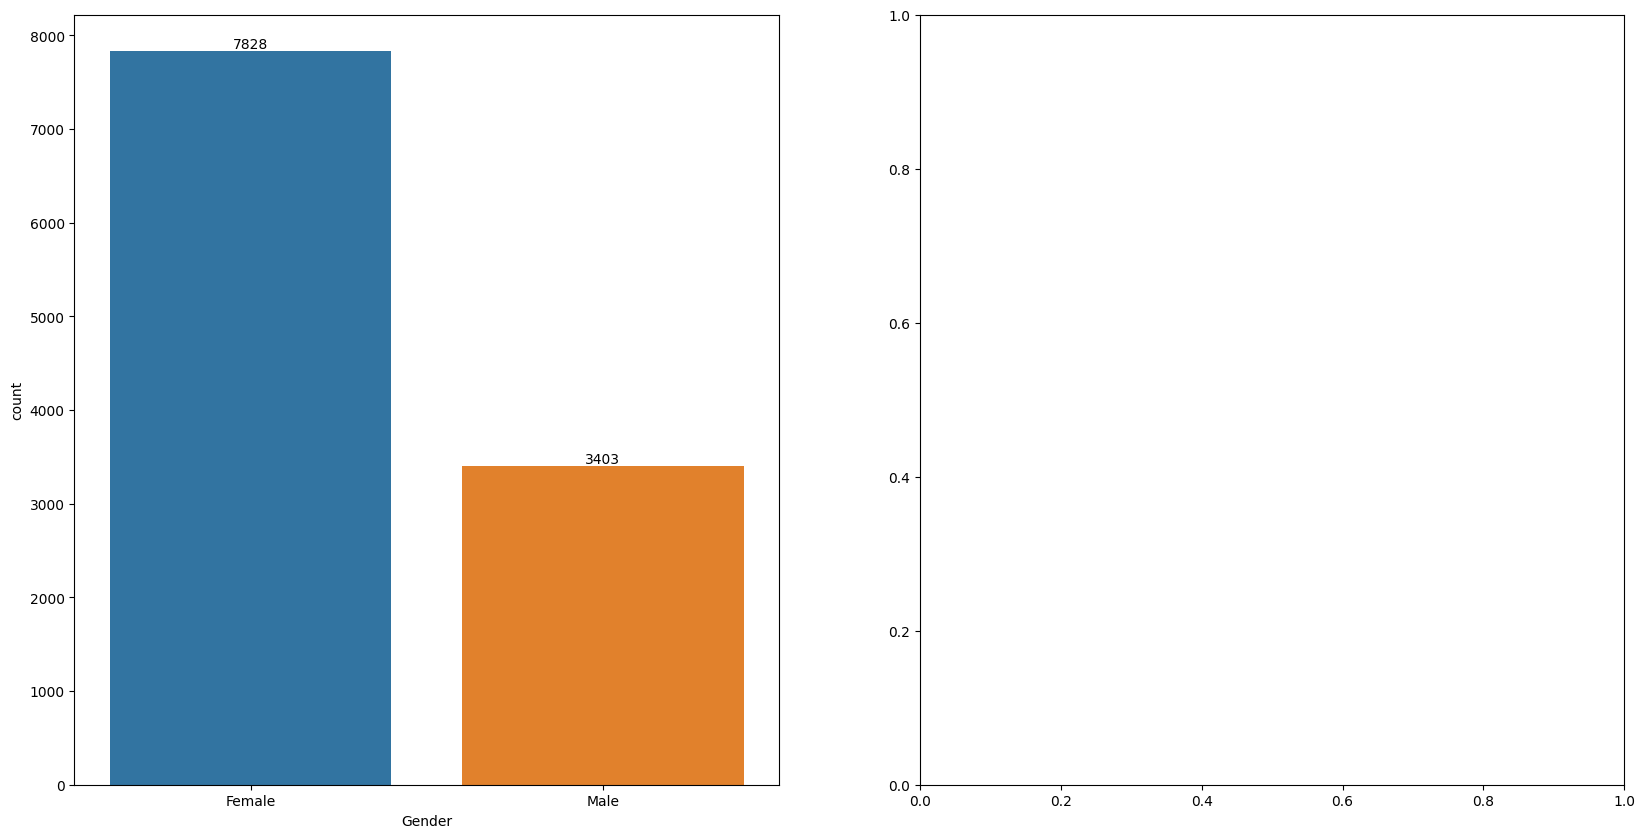

In [29]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (20, 10))
count_gen = sns.countplot(x = 'Gender', data = sales, hue = 'Gender', ax = axes[0])
label(count_gen)

In [30]:
Group_gender = sales.groupby('Gender')['Amount'].sum()

In [31]:
Group_gender

Gender
Female    74307682.43
Male      31871146.00
Name: Amount, dtype: float64

In [32]:
Group_gender = pd.DataFrame(Group_gender)
Group_gender.reset_index(inplace = True)
Group_gender

,Gender,Amount
0,Female,74307682.43
1,Male,31871146.00


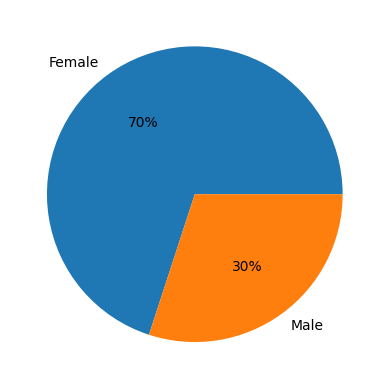

In [33]:
plt.pie(Group_gender['Amount'], labels = Group_gender['Gender'].unique(), autopct = '%0.0f%%')
plt.show()

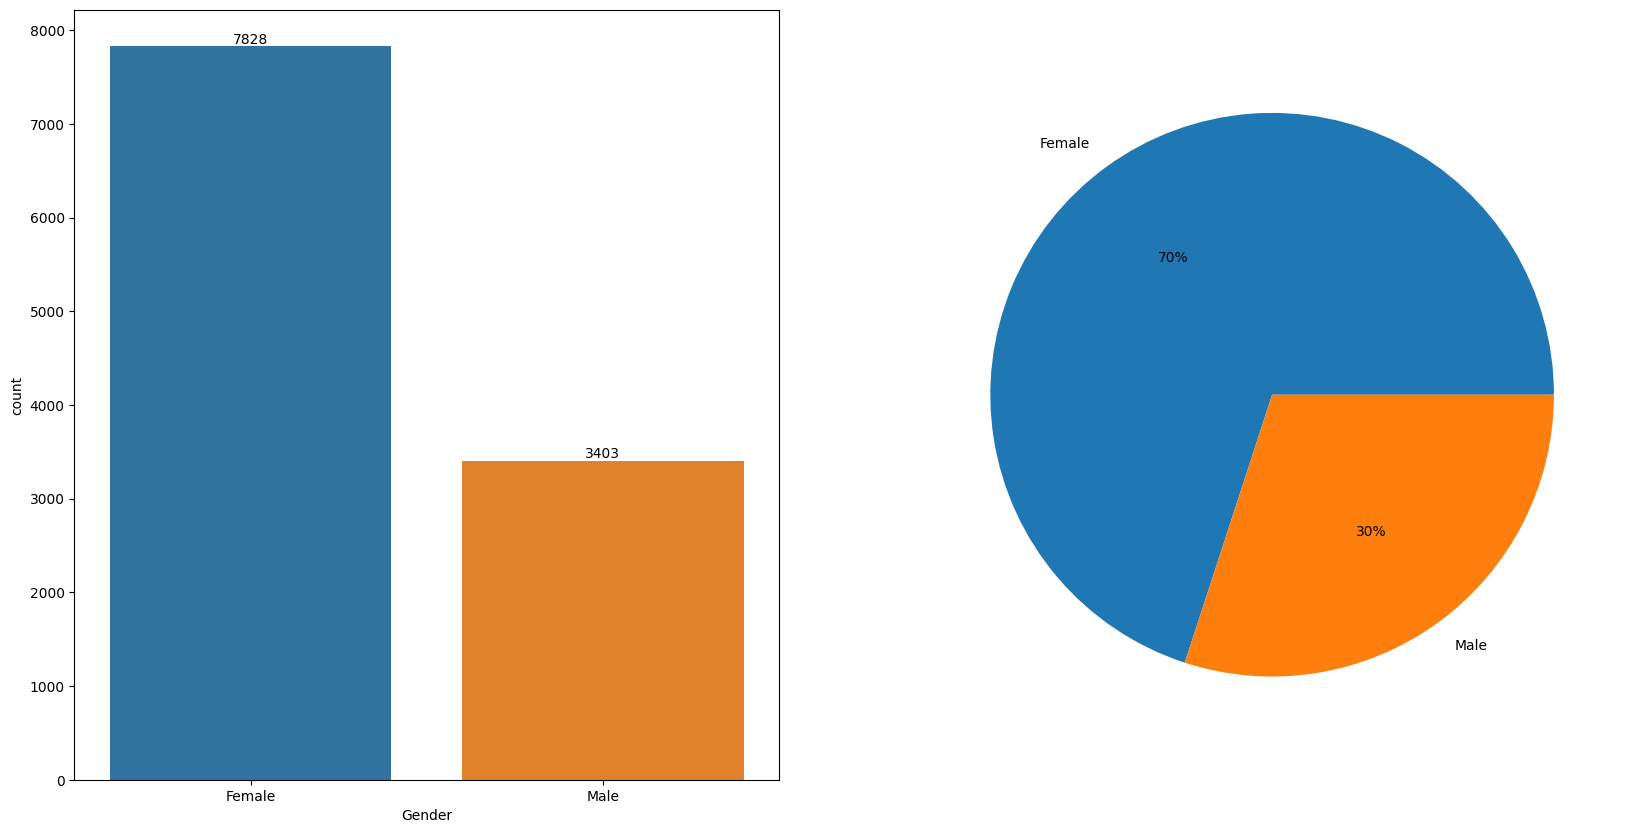

In [34]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (20, 10))
count_gen = sns.countplot(x = 'Gender', data = sales, hue = 'Gender', ax = axes[0])
label(count_gen)
Group_gender = pd.DataFrame(Group_gender)
Group_gender.reset_index(inplace = True)
plt.pie(Group_gender['Amount'], labels = Group_gender['Gender'].unique(), autopct = '%0.0f%%')
plt.show()

#### Females are more spending on shopping

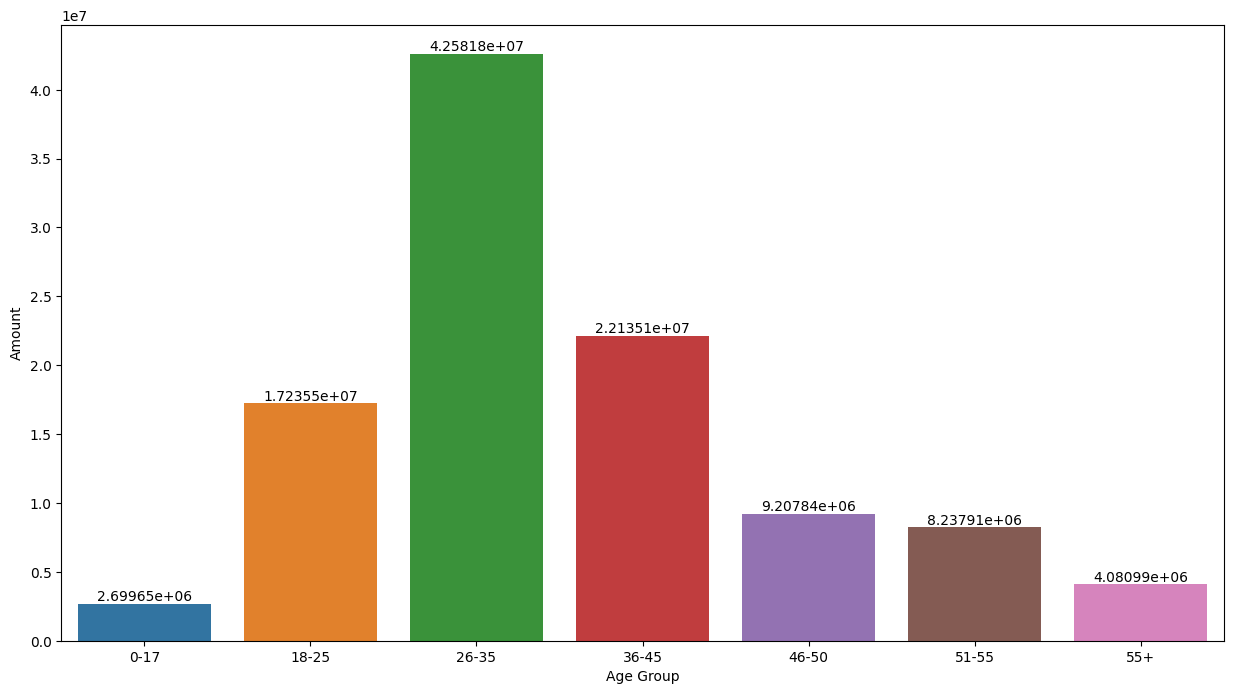

In [35]:
# Who spend more on shopping by age group:
plt.figure(figsize = (15,8))
age_group = sales.groupby('Age Group')['Amount'].sum() 
age_group = pd.DataFrame(age_group)
a = sns.barplot(x = age_group.index, y = 'Amount', data = age_group, hue = 'Age Group')
label(a)

#### The age group between 26 to 35 is spending more money on shopping

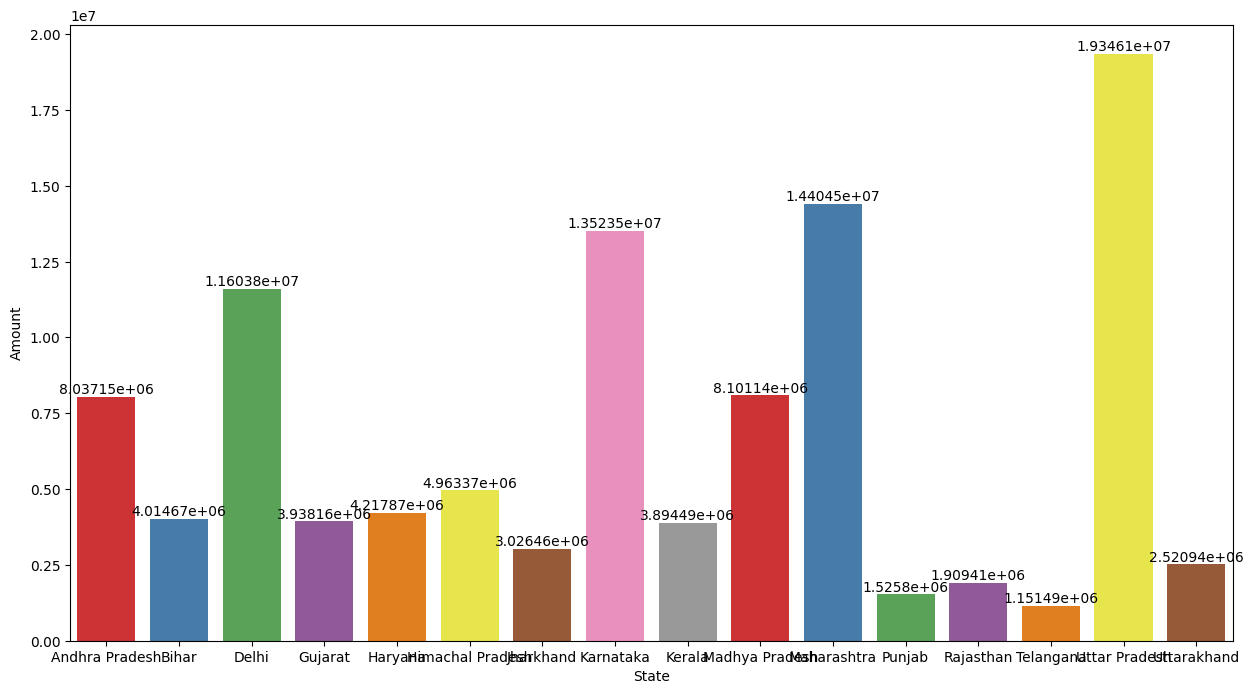

In [36]:
# Who is spending more money based on state.
plt.figure(figsize = (15,8))
state_group = sales.groupby('State')['Amount'].sum() 
state_group = pd.DataFrame(state_group)
state_group.reset_index(inplace = True)
b = sns.barplot(x = 'State', y = 'Amount', data = state_group, hue = 'State', palette ='Set1')

for i in b.containers:
    b.bar_label(i)
    
label(a)

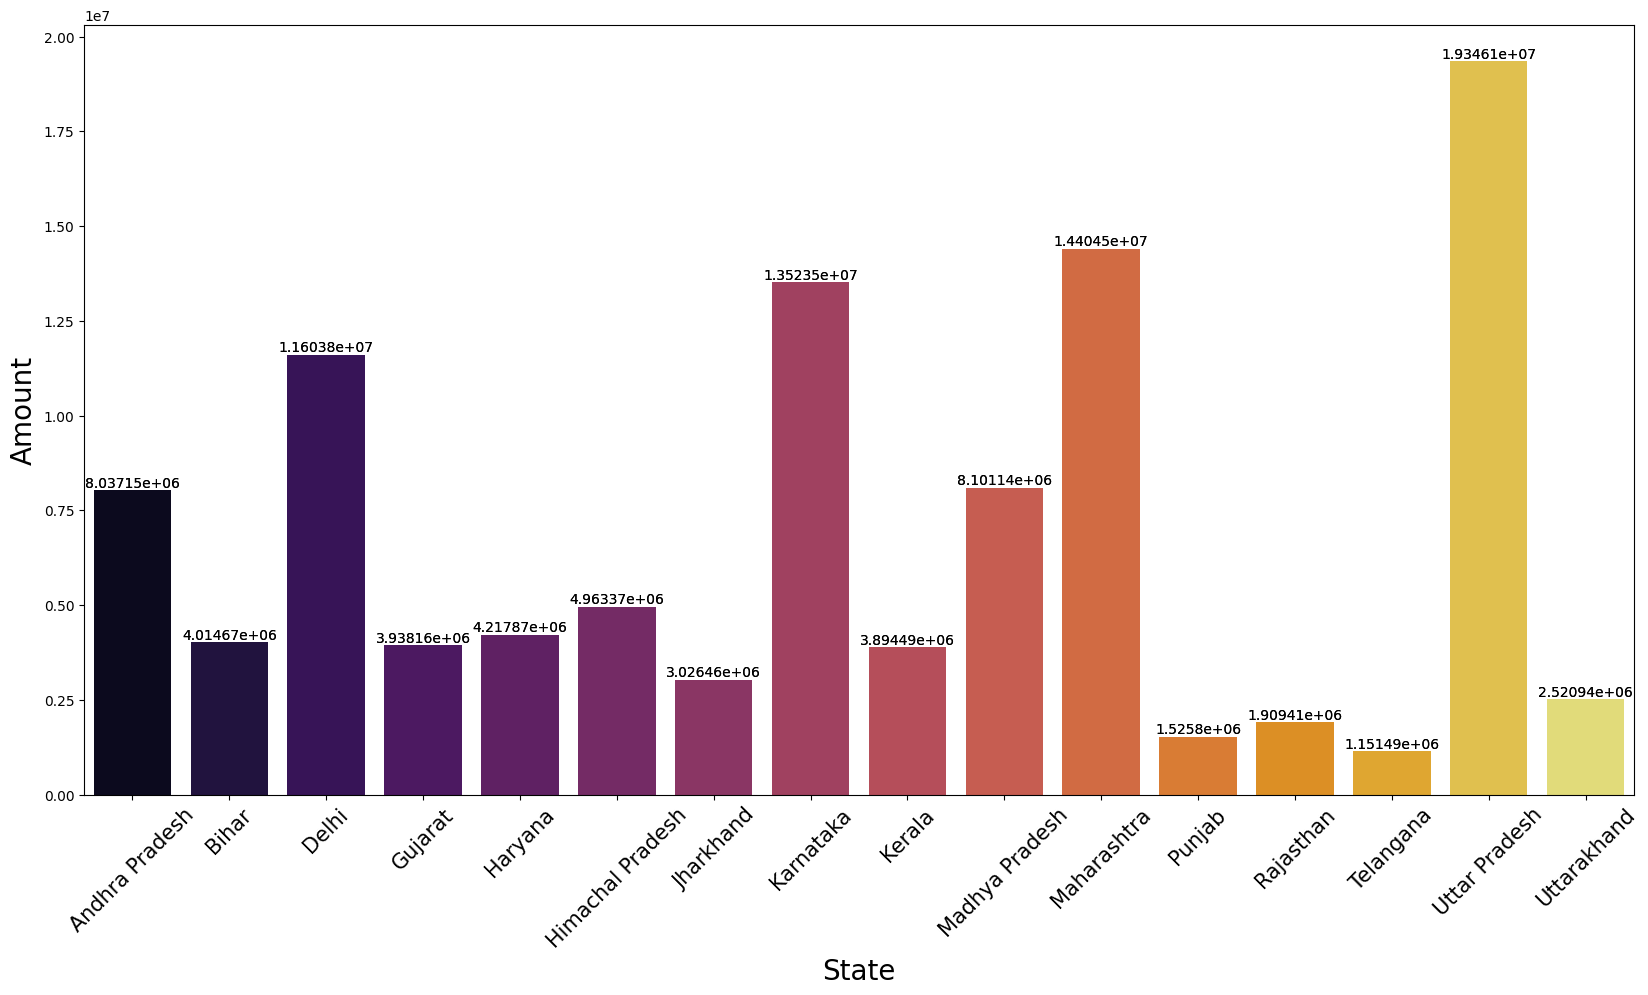

In [37]:
# Who is spending more money based on state.
plt.figure(figsize = (20,10))
state_group = sales.groupby('State')['Amount'].sum() 
state_group = pd.DataFrame(state_group)
state_group.reset_index(inplace = True)
plt.xticks(rotation = 45, fontsize = 15)
plt.xlabel('State', fontsize = 20)
plt.ylabel('Amount', fontsize = 20)

b = sns.barplot(x = 'State', y = 'Amount', data = state_group, hue = 'State', palette ='inferno')

for i in b.containers:
    b.bar_label(i)
    
label(b)

#### Utter Pradesh is spending more money on shopping 

In [38]:
sales.head()

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,Female,26-35,28,Single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,Female,26-35,35,Married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,Female,26-35,35,Married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,Male,0-17,16,Single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,Male,26-35,28,Married,Gujarat,Western,Food Processing,Auto,2,23877.0


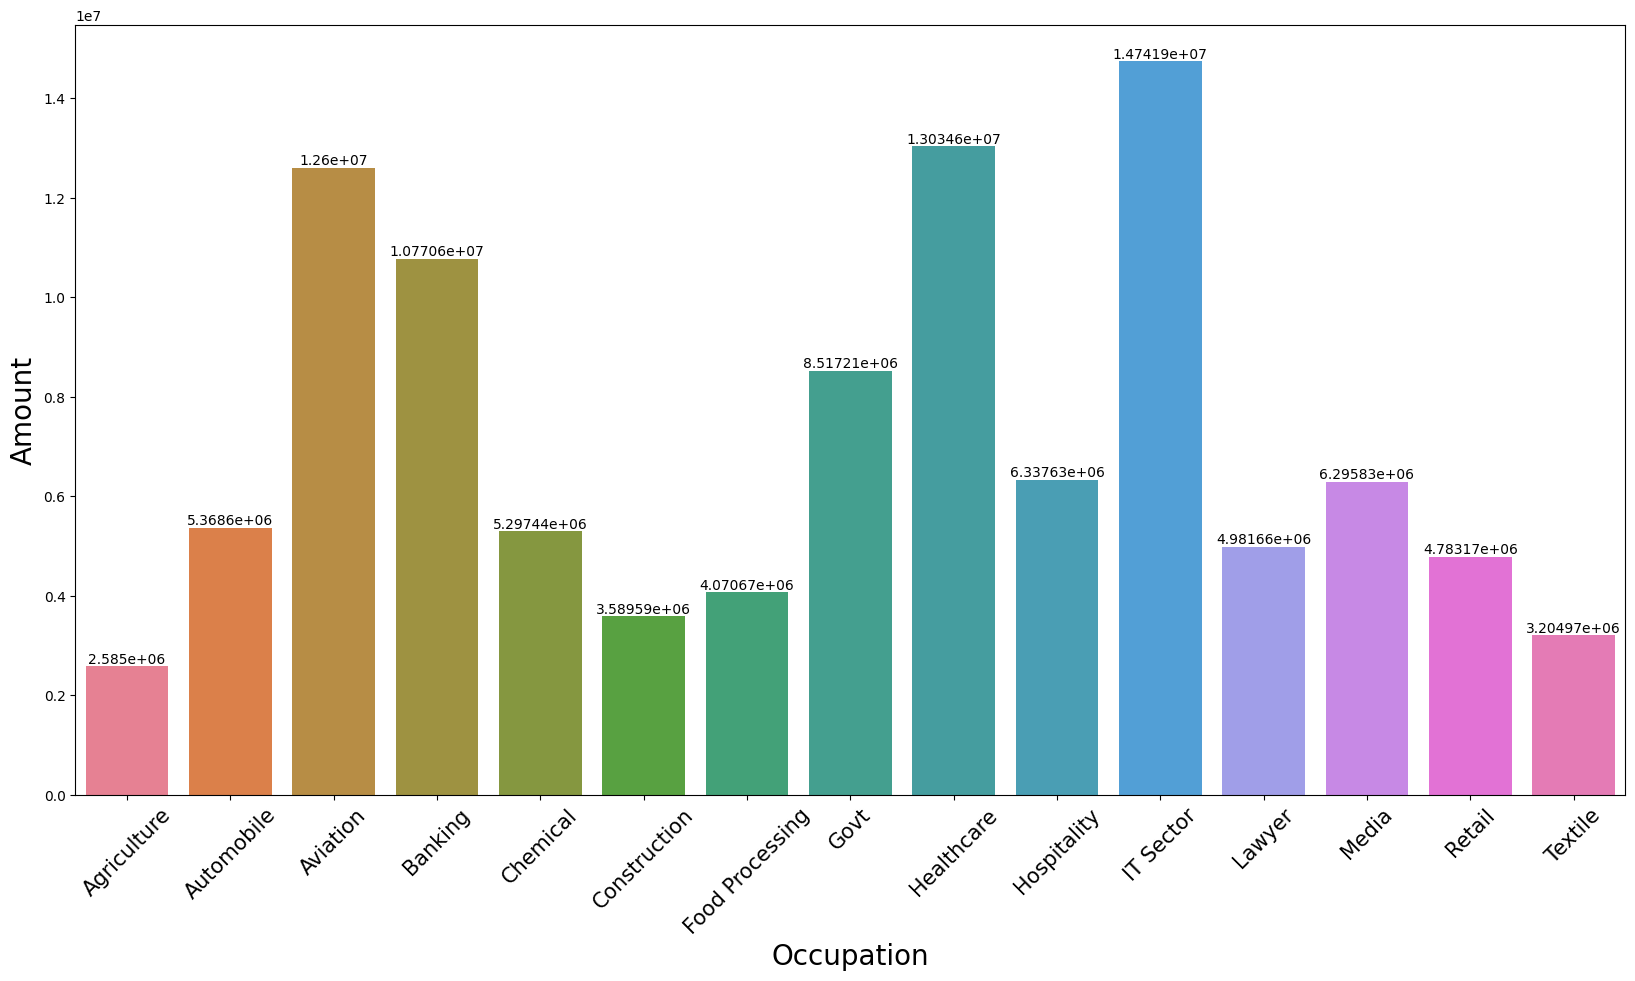

In [39]:
# Who is spending more money based on occupation.
plt.figure(figsize = (20, 10))
occupation_group = sales.groupby('Occupation')['Amount'].sum()
occupation_group = pd.DataFrame(occupation_group)
occupation_group.reset_index(inplace = True)
plt.xticks(rotation = 45, fontsize = 15)
plt.xlabel('Occupation', fontsize = 20)
plt.ylabel('Amount', fontsize = 20)
c = sns.barplot(x = 'Occupation', y = 'Amount', data = occupation_group, hue = 'Occupation', errorbar = None)

for i in c.containers:
    c.bar_label(i)

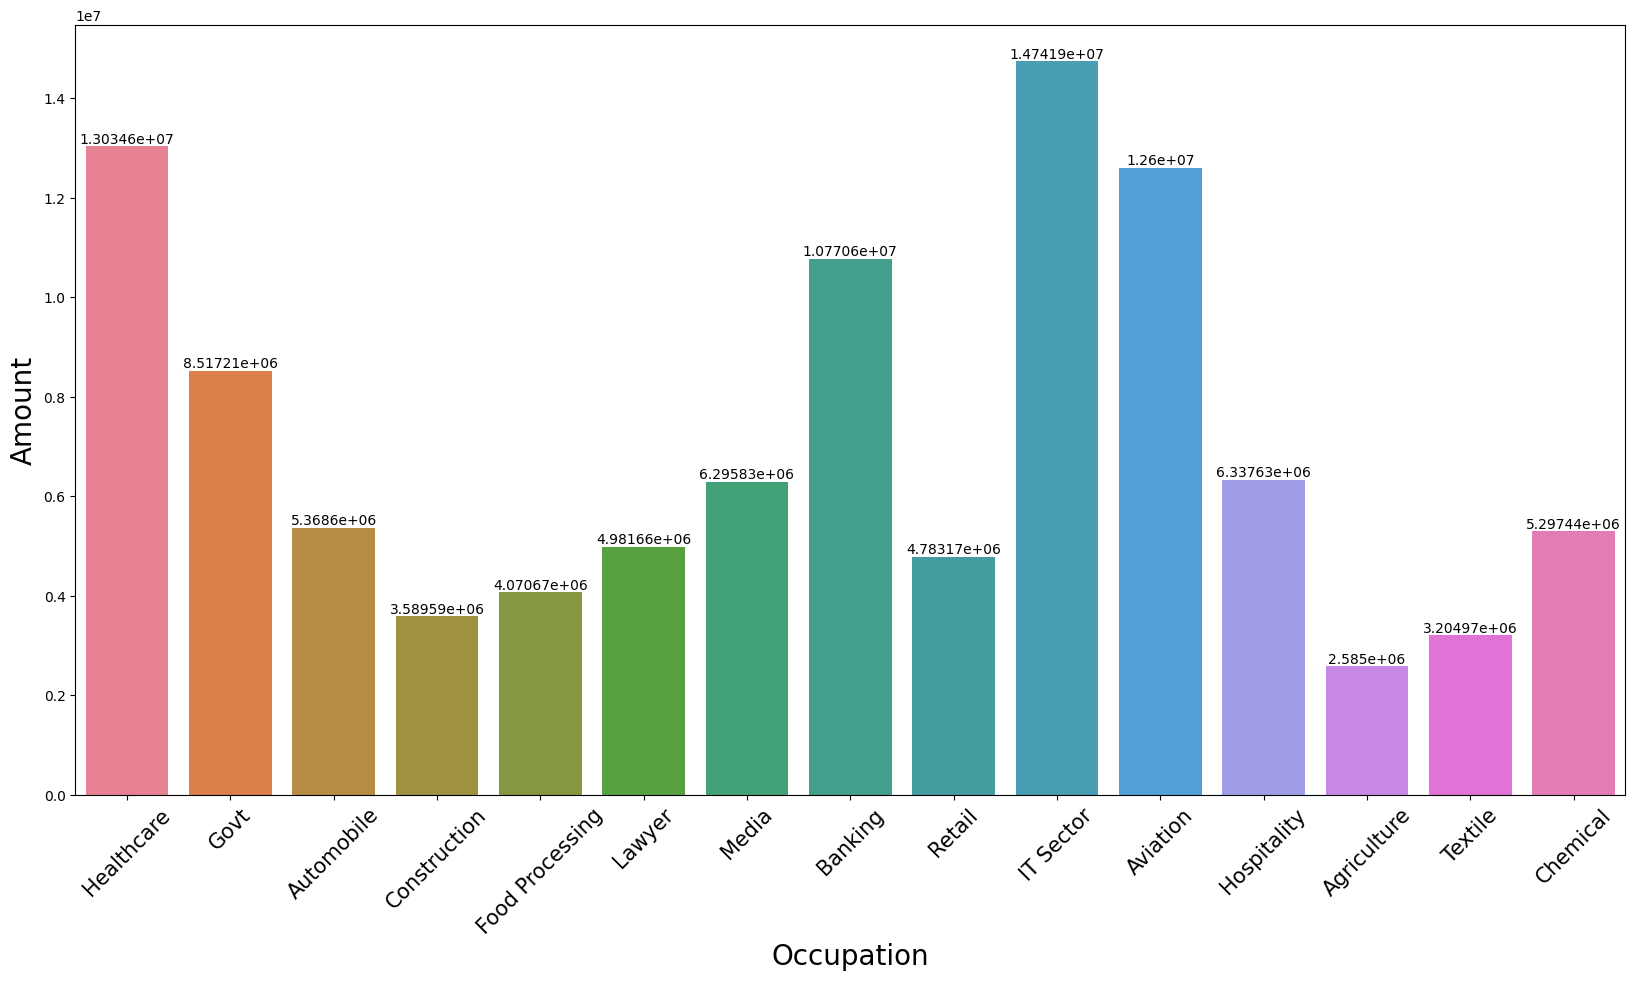

In [40]:
# Alternate method :
plt.figure(figsize = (20, 10))
plt.xticks(rotation = 45, fontsize = 15)
plt.xlabel('Occupation', fontsize = 20)
plt.ylabel('Amount', fontsize = 20)
a = sns.barplot(x = 'Occupation', y = 'Amount', data = sales, hue = 'Occupation', errorbar = None, estimator = sum)
label(a)


#### IT Sector is spending more money on shopping

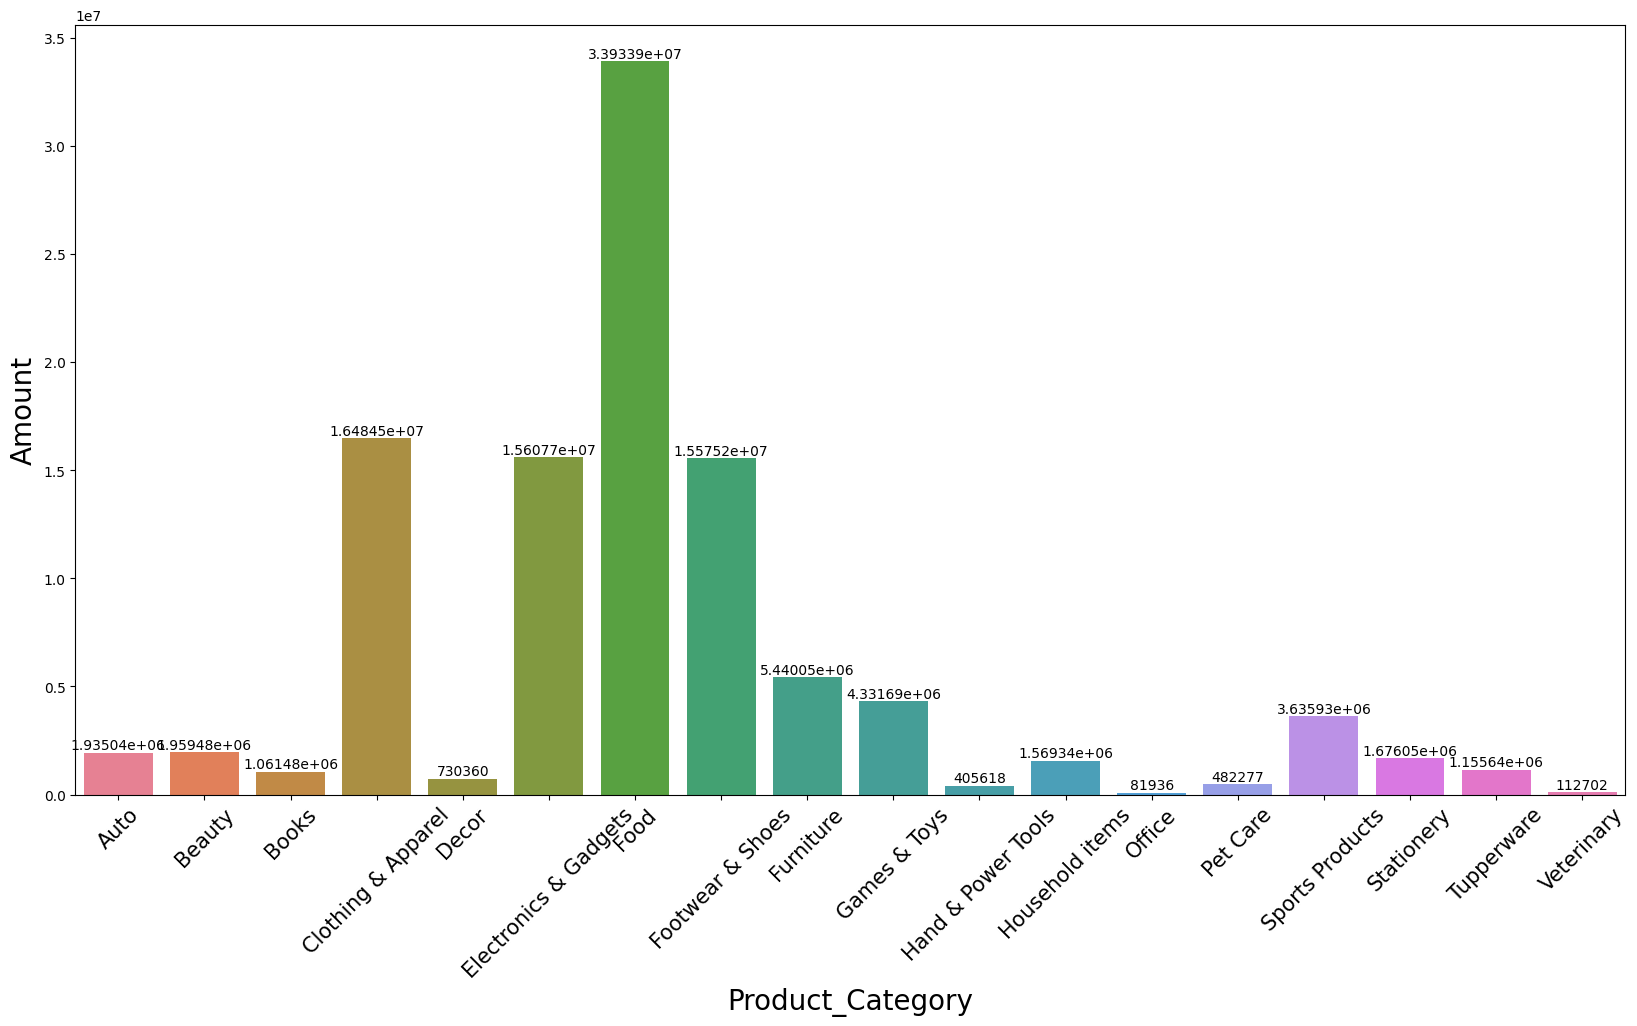

In [41]:
# Who is spending more money based on Product_category.

plt.figure(figsize = (20, 10))
Product_category_group = sales.groupby('Product_Category')['Amount'].sum()
Product_category_group = pd.DataFrame(Product_category_group)
Product_category_group.reset_index(inplace = True)
plt.xticks(rotation = 45, fontsize = 15)
plt.xlabel('Product_Category', fontsize = 20)
plt.ylabel('Amount', fontsize = 20)
x = sns.barplot(x = 'Product_Category', y = 'Amount', data = Product_category_group, hue = 'Product_Category', errorbar = None)
for i in x.containers:
    x.bar_label(i)

#### Females are spending more money on food, Clothing, Electronic gadgets and footwear.

### Conclusion :
### Based on above analysis i can conclude that :
#### Females of 26-35 age group from uttar Pradesh, Maharastra, Karnataka working it IT, HealthCare and Aviation spend more money on food, cloths & footwear and Electronic Gadgets.

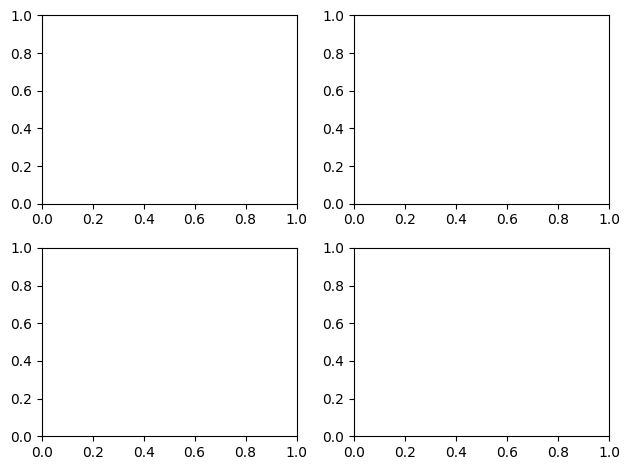

In [47]:
plt.subplot(2,2,1)
plt.subplot(2,2,2)
plt.subplot(2,2,3)
plt.subplot(2,2,4)
plt.tight_layout()


In [48]:
plt.figure(figsize = (10, 10), facecolor = 'pink')
plt.

<Figure size 2000x1000 with 0 Axes>

<Figure size 2000x1000 with 0 Axes>